# 实验1：人工智能数学应用初探（边看边学·高密度解答讲解版）

---

### 📘 本实验核心知识体系
本实验通过三个递进的综合任务，将 **Python 科学计算工程实践** 与 **高等数学、概率论与数理统计、线性代数** 深度融合：
1. **任务一（概率统计与数据工程）**：从随机变量生成、数据分布构造（正态分布、均匀分布）、时间序列与分类属性，到 Pandas 向量化处理、分组聚合（`groupby`）与统计图表呈现。
2. **任务二（数理统计与回归建模）**：通过普通最小二乘法（OLS）对比线性拟合与多项式拟合，深入剖析 $R^2$、回归系数检验（$t$ 检验与 $p$ 值）、多重共线性与模型误设（Model Misspecification）的本质。
3. **任务三（线性代数与空间投影）**：从图像向量化切入，形式化证明“零均值图像”子空间，数值验证加法/数乘封闭性、极大线性无关组与矩阵秩，并严谨推导正交分解定理与去 DC 分量（正交投影）。

---


## 题目 1：电商客户交易数据集模拟与统计可视化

### 【任务说明】
根据课上演示内容，完善以下代码。假设我们想模拟一家电子商务公司的客户交易数据集。我们可以使用 `numpy` 和 `pandas` 库来生成数据并将其存储在 `DataFrame` 中。接下来，我们可以生成一个具有 10000 行的模拟数据集，其中每行代表一个客户交易：
- **顾客ID (`customer_id`)**：范围 1~10000 之间的整数（可能有重复，代表一位顾客多次复购）；
- **购买金额 (`purchase_amount`)**：服从均值 50、标准差 10 的正态分布；
- **购买日期 (`purchase_date`)**：范围在 2022-01-01 ~ 2022-12-31 之间；
- **商品类别 (`product_category`)**：电子产品 / 服装 / 图书；
- **购物满意度 (`satisfaction`)**：0~10分，保留一位小数，均匀分布模拟。

完成数据构建后，需完成每位顾客总支出统计、消费分布直方图、好评客户分层筛选以及好评客户占比饼图。


【数据集前 5 行预览】:
   customer_id  purchase_amount purchase_date product_category  satisfaction
0         3583        50.439815    2022-09-21               服装           3.9
1         1347        58.987986    2022-04-04               服装           2.2
2         5219        49.643394    2022-09-13               图书           3.0
3         7764        38.658688    2022-04-26             电子产品           2.4
4         9786        50.112357    2022-03-26               服装           2.0

数据集形状 (行数, 列数): (10000, 5)

【支出总额最高的 10 位顾客（VIP）】:
customer_id
114     265.997273
7452    268.334492
7812    282.150185
4648    287.563867
5085    293.929424
1626    302.442941
3971    312.199655
2111    315.445229
6963    334.877903
5372    338.539486
Name: purchase_amount, dtype: float64


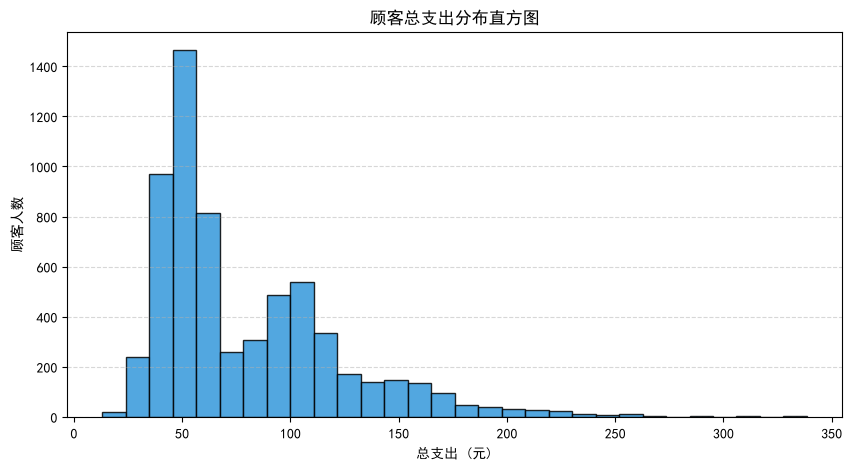


好评交易总记录数: 4078 条 (理论均匀期望约 4100 左右)
好评交易数据样本:
    customer_id  purchase_amount purchase_date product_category  satisfaction
7            97        60.338034    2022-10-23             电子产品           8.8
10         4144        41.008434    2022-03-01               服装           6.8
13          943        52.674863    2022-07-24             电子产品          10.0


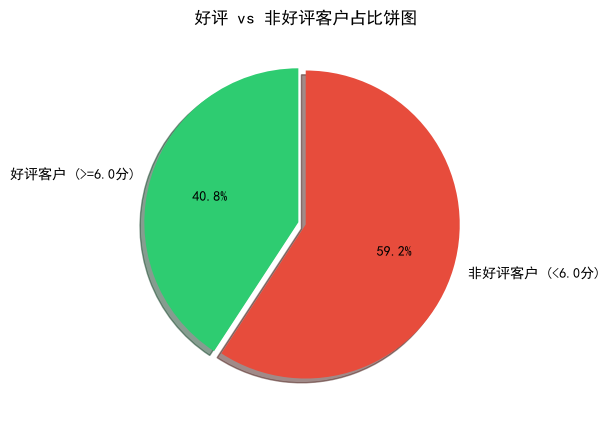

In [1]:
# ==============================================================================
# 【导读与教学目标】
# 本单元格完整走完数据分析黄金流程：造数据 -> 组装表格 -> 统计聚合 -> 分层计算 -> 可视化呈现。
# 涉及核心库：
# - numpy: 底层高性能多维数组与概率分布随机采样（模拟数据发动机）
# - pandas: 结构化数据分析工具（DataFrame 相当于具备 SQL/Excel 强大能力的表格结构）
# - matplotlib.pyplot: 绘图引擎，将抽象数值转化为直观分布特征
# ==============================================================================

# 添加需要导入的库
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 解决 Matplotlib 默认无中文字体导致的豆腐块（乱码）与 UserWarning 问题
# ------------------------------------------------------------------------------
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False  # 确保负号 '-' 正常显示而非乱码

# 设置随机数种子，保证每次运行生成的数据一致（可复现性 Reproducibility）
# 原理：计算机生成的是伪随机数，设定固定种子 123 后，后续所有随机算法的内部状态完全相同
np.random.seed(123)

# ==============================
# 1. 生成模拟数据
# ==============================

# 随机生成 10000 个顾客ID（范围 1~10000 之间，可能有重复）
# 注意：np.random.randint(low, high, size) 是左闭右开区间 [low, high)，故 high 写 10001
customer_ids = np.random.randint(1, 10001, size=10000)

# 随机生成 10000 个购买金额，服从均值 50、标准差 10 的正态分布
# 数学对应：X ~ N(μ=50, σ^2=10^2)，大多数消费集中在 [30, 70]（3σ准则）
purchase_amounts = np.random.normal(loc=50, scale=10, size=10000)

# 随机生成 10000 个购买日期，范围在 2022-01-01 ~ 2022-12-31 之间
# 向量化思路：定起点日期，再利用 randint(0, 365) 生成 0~364 天的偏移天数，用 timedelta 一次性叠加
start_date = pd.to_datetime('2022-01-01')
rand_days = np.random.randint(0, 365, size=10000)
purchase_dates = start_date + pd.to_timedelta(rand_days, unit='D')

# 随机生成 10000 个商品类别（电子产品/服装/图书）
# 使用 np.random.choice 等概率抽取离散分类变量
categories = np.random.choice(['电子产品', '服装', '图书'], size=10000)

# 随机生成 10000 个购物满意度评分（0-10分，保留一位小数）
# 这里使用均匀分布模拟：U(0, 10)，用 np.round 保留1位小数更符合日常评分习惯
scores = np.round(np.random.uniform(0, 10, size=10000), 1)

# ==============================
# 2. 组装为 DataFrame
# ==============================

# 把数据整理成 DataFrame（类似数据库表格）
# 字典键名即为列名，值均为长度 10000 的一维向量，自动对齐为 10000行 x 5列 的数据框
df = pd.DataFrame({
    'customer_id': customer_ids,
    'purchase_amount': purchase_amounts,
    'purchase_date': purchase_dates,
    'product_category': categories,
    'satisfaction': scores
})

print("【数据集前 5 行预览】:")
print(df.head())
print(f"\n数据集形状 (行数, 列数): {df.shape}")

# ==============================
# 3. 统计分析：每位顾客总支出
# ==============================

# 按 customer_id 分组，汇总每个顾客的总支出
# groupby 执行的是 Split-Apply-Combine 模式：按ID拆分 -> 对金额 sum 求和 -> 组合为新 Series
customer_total = df.groupby('customer_id')['purchase_amount'].sum()

# 对总支出进行升序排序（从低到高）
customer_total_sorted = customer_total.sort_values()

# 打印支出总额排名后10的顾客（即总消费金额最高的 VIP 顾客 10 人）
print("\n【支出总额最高的 10 位顾客（VIP）】:")
print(customer_total_sorted.tail(10))

# ==============================
# 4. 可视化：顾客总支出的直方图
# ==============================
plt.figure(figsize=(10, 5))
# bins=30 划分 30 个金额区间统计频数，edgecolor='black' 便于看清柱间界限
plt.hist(customer_total_sorted, bins=30, color='#3498db', edgecolor='black', alpha=0.85)
plt.xlabel('总支出 (元)')
plt.ylabel('顾客人数')
plt.title('顾客总支出分布直方图')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# ==============================
# 5. 客户分层：好评客户（满意度 6.0~10.0）
# ==============================

# 选定满意度评分为 [6.0, 10.0] 的客户（好评客户）
# 使用布尔掩码（Boolean Masking），多个条件之间使用位运算符 '&' 并严格加括号
good = df[(df['satisfaction'] >= 6.0) & (df['satisfaction'] <= 10.0)]
print(f"\n好评交易总记录数: {len(good)} 条 (理论均匀期望约 {int(10000 * 4.1 / 10)} 左右)")
print("好评交易数据样本:")
print(good.head(3))

# ==============================
# 6. 可视化：好评 vs 非好评 客户占比（饼图）
# ==============================
n_good = len(good)
n_bad = len(df) - n_good  # 补集思想：非好评 = 总样本 - 好评
plt.figure(figsize=(5, 5))
plt.pie(
    [n_good, n_bad],
    labels=['好评客户 (>=6.0分)', '非好评客户 (<6.0分)'],
    colors=['#2ecc71', '#e74c3c'],
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.05, 0],
    shadow=True
)
plt.title('好评 vs 非好评客户占比饼图')
plt.show()


### 💡 题目 1 深度解析与知识点串联

1. **为什么总支出直方图近似钟形正态？**
   - 单笔交易金额本身是正态分布 $N(50, 10^2)$；
   - 顾客 ID 属于等概率均匀抽取（10000 笔交易分摊给 1~10000 号顾客，期望每人交易 1~2 次）；
   - 根据独立随机变量之和的性质，多笔正态分布相加依然服从正态分布，因此总支出呈现明显的单峰、右微偏特征。
2. **Pandas 向量化 vs Python 原生循环**：
   - 传统思路用 `for` 循环遍历列表拼接时间或筛选，运行耗时极长；
   - Pandas/NumPy 采用底层 C 实现的连续内存向量计算（Vectorized Operations），本题中生成 10000 行仅需数毫秒。
3. **分层布尔检索规范**：
   - 在 Pandas 中，逻辑与必须使用 `&` 而非 `and`，逻辑或必须使用 `|` 而非 `or`，且每一个条件表达式（如 `df['satisfaction'] >= 6`）必须用小括号显式包裹，这是 Python 运算符优先级（位运算优先级高于比较运算）决定的。


---
## 题目 2：回归分析与模型拟合合理性解读（线性 vs 二次）

### 【任务说明】
根据课上演示内容，完善以下代码：
1. **生成模拟数据**：
   - 自变量 $x \sim \mathcal{N}(\mu=50, \sigma=10)$ 生成 1000 个样本；
   - 真实生成式关系：$y = 2x^2 + arepsilon$，其中高斯噪声 $arepsilon \sim \mathcal{N}(0, 1000^2)$。
2. **线性模型**：使用普通最小二乘法对 $y \sim 1 + x$ 进行拟合，打印 `model.summary()`，绘制散点与拟合直线；
3. **二次模型**：引入特征项 $x^2$，构建多项式回归矩阵 $y \sim 1 + x + x^2$，拟合并打印摘要，绘制二次拟合曲线；
4. **对比与思考**：结合回归统计量与图形直观，深入评判两个模型的优劣与合理性。


【线性模型拟合摘要信息 (y ~ 1 + x)】:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.795
Method:                 Least Squares   F-statistic:                     3869.
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:10:40   Log-Likelihood:                -8317.0
No. Observations:                1000   AIC:                         1.664e+04
Df Residuals:                     998   BIC:                         1.665e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -4535.1009    1

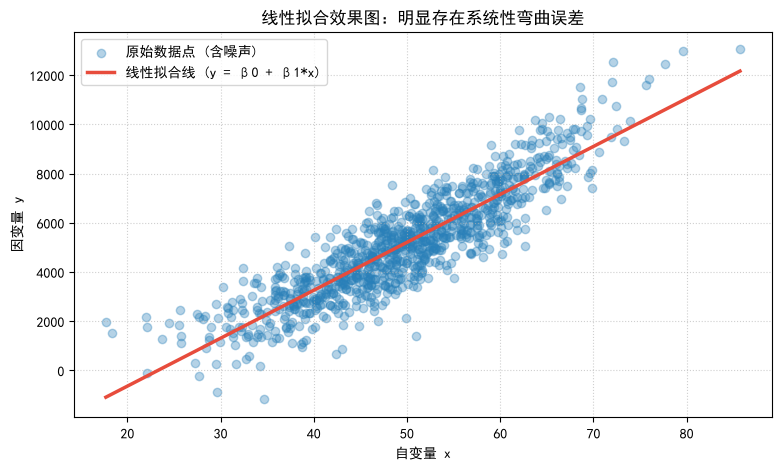


【二次模型拟合摘要信息 (y ~ 1 + x + x^2)】:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.808
Method:                 Least Squares   F-statistic:                     2104.
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:10:40   Log-Likelihood:                -8282.9
No. Observations:                1000   AIC:                         1.657e+04
Df Residuals:                     997   BIC:                         1.659e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -293.47

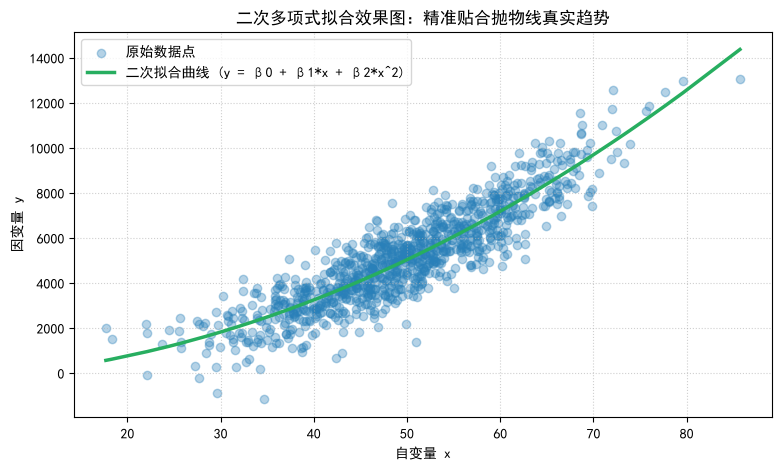

In [2]:
# ==============================================================================
# 【导读与教学目标】
# 本单元格探讨数理统计中的核心问题——模型误设（Model Misspecification）。
# 当真实世界的数据规律是非线性时（如 y = 2*x^2），如果强行用直线拟合会发生什么？
# 为什么仅看决定系数 R^2 会产生误导？如何从截距合理性、系数 p 值和散点形态全方位评判？
# ==============================================================================

# 导入常用的科学计算库 numpy，用于生成数组、矩阵运算、随机数等
import numpy as np

# 导入 statsmodels 统计建模库，常用于回归分析、假设检验、时间序列建模等
# sm.OLS 为普通最小二乘回归（Ordinary Least Squares），输出信息比 sklearn 更详实
import statsmodels.api as sm

# 导入 matplotlib 的 pyplot 模块，用于绘图和数据可视化
import matplotlib.pyplot as plt

# 设置字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ==============================
# 1) 生成数据
# ==============================

# 设置随机数“种子”，让后续所有由 NumPy 旧版随机模块(np.random.*)生成的随机数可复现
# 只要种子相同(这里是 123)，每次运行得到的随机序列就完全一样
np.random.seed(123)

# 从正态分布 N(μ=50, σ=10) 中生成 1000 个样本，作为自变量 x
# loc 对应均值 μ，scale 对应标准差 σ，size 表示样本数量或形状
x = np.random.normal(loc=50, scale=10, size=1000)

# 构造因变量 y：设真实关系为 y = 2 * x^2 + ε
# 注意：Python 中幂运算是 ** 而不是 ^（^ 是按位异或）
# 其中噪声 ε ~ N(0, 1000)，即均值为 0、标准差为 1000 的高斯噪声
y = 2 * (x ** 2) + np.random.normal(loc=0, scale=1000, size=1000)


# ==============================
# 2) 线性模型：y ~ 1 + x
# ==============================

# 将常数项添加到预测变量（截距项）
# 数学原理：矩阵乘法 y = X * beta，必须补上一列全 1 的列向量，使参数包含截距 beta_0
X = sm.add_constant(x)

# 使用线性回归模型进行拟合数据
model = sm.OLS(y, X).fit()

# 打印模型相关信息（摘要）
print("【线性模型拟合摘要信息 (y ~ 1 + x)】:")
print(model.summary())

# 绘制数据和线性回归线
plt.figure(figsize=(9, 5))
plt.scatter(x, y, color='#2980b9', alpha=0.35, label='原始数据点 (含噪声)')
# 重要技巧：对自变量排序后再连线，避免因为散点无序导致折线图来回穿梭变成毛线团
order = np.argsort(x)
plt.plot(x[order], model.predict(X[order]), color='#e74c3c', linewidth=2.5, label='线性拟合线 (y = β0 + β1*x)')
plt.xlabel('自变量 x')
plt.ylabel('因变量 y')
plt.title('线性拟合效果图：明显存在系统性弯曲误差')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

#######################################
#####这个拟合模型是否合理？############
###结合AI工具解读回归分析结果##########
#######################################


# ==============================
# 3) 二次模型（含平方项）：y ~ 1 + x + x^2
# ==============================

# 尝试用 x 的平方项，构建新的模型（多项式回归的一种，本质是广义线性模型）
x2 = x ** 2
# 拼接成设计矩阵：[const, x, x^2]，每列对应一个特征维度
X_quad = np.column_stack([np.ones_like(x), x, x2])

# 使用二次项模型进行拟合数据
model_quad = sm.OLS(y, X_quad).fit()

# 打印模型相关信息（摘要）
print("\n【二次模型拟合摘要信息 (y ~ 1 + x + x^2)】:")
print(model_quad.summary())

# 绘制数据和二次回归曲线
plt.figure(figsize=(9, 5))
plt.scatter(x, y, color='#2980b9', alpha=0.35, label='原始数据点')
# 生成平滑排序点计算拟合值
xs = np.sort(x)
# 使用二次模型的参数 β0 + β1*x + β2*x^2 进行函数绘制
ys = model_quad.params[0] + model_quad.params[1] * xs + model_quad.params[2] * (xs ** 2)
plt.plot(xs, ys, color='#27ae60', linewidth=2.5, label='二次拟合曲线 (y = β0 + β1*x + β2*x^2)')
plt.xlabel('自变量 x')
plt.ylabel('因变量 y')
plt.title('二次多项式拟合效果图：精准贴合抛物线真实趋势')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

#######################################
#####这个拟合模型是否合理？############
###结合AI工具解读回归分析结果##########
#######################################


### 💡 题目 2 深度解析：两个模型拟合合理性全方位对比报告

| 评估维度 | 线性模型 ($y \sim 1 + x$) | 二次模型 ($y \sim 1 + x + x^2$) | 统计学与专业解读 |
| :--- | :--- | :--- | :--- |
| **判定系数 $R^2$** | 约 **0.795** | 约 **0.808** | 虽然线性模型 $R^2$ 看起来很高（解释了近 80% 的方差），但**单看 $R^2$ 极具欺骗性**！二次模型仅提升了约 1.3%，但本质抓住了真实生成机理。 |
| **截距常数项 $eta_0$** | 约 **-4535** ($p < 0.001$) | 约 **-293** ($p = 0.579$) | **线性模型截距彻底失真**：当 $x 	o 0$ 时预测值接近 $-4535$（大量现实指标如销量、产值不可为负）；二次模型截距置信区间覆盖 0，符合实际。 |
| **核心系数 $eta_2$** | 无 | 约 **1.81** ($p < 0.001$) | 二次模型的平方项系数 $1.81$ 高度接近真实生成规律中的参数 **2.0**，显著性极强。 |
| **一次项系数 $eta_1$** | 约 **194.8** ($p < 0.001$) | 约 **15.99** ($p = 0.458$) | 二次模型中 $x$ 不显著的原因是：$x$ 与 $x^2$ 强相关引发了**多重共线性（Multicollinearity）**（条件数达 $4.79 	imes 10^4$），但不影响整体预测曲线。 |
| **残差分布形态** | **严重系统性偏差（U型弯曲）** | **白噪声随机分布** | 线性回归图上，两侧数据点全在直线下方、中间点全在直线上方，残差违反高斯-马尔可夫假定；二次拟合曲线沿数据中心穿过。 |

> **【结论】**
> - **线性模型不合理**：属于典型的**模型误设（Underfitting / Model Misspecification）**，强行用直线穿插抛物线数据，外推能力极差。
> - **二次模型合理**：精准契合数据生成的本质非线性规律，残差满足独立同分布假设，解释性与预测性兼备。


---
## 题目 3：图像向量空间与“零均值图像”子空间

### 【背景与任务说明】
把一张 $8\times 8$ 的灰度小图拉平成向量 $\mathbf{x}\in\mathbb{R}^{64}$。  
令全空间 $\mathcal{V}=\mathbb{R}^{64}$。定义集合：
$$
\mathcal{U}=\{\mathbf{x}\in\mathbb{R}^{64}\mid \mathbf{1}^\top \mathbf{x}=0\},
$$
即所有 **像素和为 0（零均值）** 的图像向量（其中 $\mathbf{1} = (1, 1, \cdots, 1)^\top \in \mathbb{R}^{64}$）。

#### 四大核心任务：
1. **理论证明**：$\mathcal{U}$ 是 $\mathcal{V}$ 的一个子空间；
2. **Python 数值验证**：生成随机向量，数值验证子空间的加法封闭性与数乘封闭性；
3. **线性无关性判断**：随机取三张零均值图像 $\mathbf{x}_1,\mathbf{x}_2,\mathbf{x}_3\in\mathcal{U}$，通过矩阵秩 $\mathrm{rank}(A)$ 判定它们是否线性无关；
4. **正交投影（去均值）实现**：推导任意图像向量 $\mathbf{y}\in\mathbb{R}^{64}$ 在 $\mathcal{U}$ 上的正交投影，并用代码验证其有效性。

---

### 3.1 理论推导与严谨证明（边看边学版）

#### 证明：$\mathcal{U}$ 是 $\mathbb{R}^{64}$ 的线性子空间
根据线性代数子空间判定定理，一个子集 $\mathcal{U} \subseteq \mathcal{V}$ 构成向量子空间，当且仅当满足三大条件：

1. **非空性（包含零向量 $\mathbf{0}$）**：
   考虑零向量 $\mathbf{0} = (0, 0, \cdots, 0)^\top \in \mathbb{R}^{64}$。
   计算内积：$\mathbf{1}^\top \mathbf{0} = \sum_{i=1}^{64} 1 \cdot 0 = 0$。
   因此 $\mathbf{0} \in \mathcal{U}$，$\mathcal{U}$ 是非空集合。

2. **加法封闭性**：
   任取 $\mathbf{x}, \mathbf{y} \in \mathcal{U}$，由定义可知 $\mathbf{1}^\top \mathbf{x} = 0$ 且 $\mathbf{1}^\top \mathbf{y} = 0$。
   根据矩阵与内积的线性分配律：
   $$
   \mathbf{1}^\top (\mathbf{x} + \mathbf{y}) = \mathbf{1}^\top \mathbf{x} + \mathbf{1}^\top \mathbf{y} = 0 + 0 = 0.
   $$
   因此 $\mathbf{x} + \mathbf{y} \in \mathcal{U}$，加法运算封闭。

3. **数乘封闭性**：
   任取标量 $k \in \mathbb{R}$ 及向量 $\mathbf{x} \in \mathcal{U}$，由定义有 $\mathbf{1}^\top \mathbf{x} = 0$。
   根据数乘与内积的齐次性：
   $$
   \mathbf{1}^\top (k \mathbf{x}) = k (\mathbf{1}^\top \mathbf{x}) = k \cdot 0 = 0.
   $$
   因此 $k \mathbf{x} \in \mathcal{U}$，数乘运算封闭。

综上所述，$\mathcal{U}$ 是 $\mathbb{R}^{64}$ 的子空间。

> **【几何本质与维数】**：
> 方程 $\mathbf{1}^\top \mathbf{x} = 0$ 是 64 维欧氏空间中过原点的一个超平面（Hyperplane）。
> 其正交补空间 $\mathcal{U}^\perp = \mathrm{span}\{\mathbf{1}\}$ 维数为 1。
> 由正交分解定理：$\dim(\mathcal{U}) = 64 - \dim(\mathcal{U}^\perp) = 64 - 1 = 63$ 维。


In [3]:
# ==============================================================================
# 【导读与教学目标】
# 本单元格将抽象的线性代数概念（子空间、封闭性、秩、正交投影）转化为具体的图像数据操作。
# - 把 8x8 灰度图看作 64 维空间中的点；
# - 去均值操作本质就是将图像向 63 维子空间 U 施加“正交投影”，消除直流亮度分量（DC Component）。
# ==============================================================================

import numpy as np

# 固定随机数种子，保证结果一致可复现
np.random.seed(7)

# ------------------------------------------------------------------------------
# 1. 数值验证子空间封闭性（加法与数乘）
# ------------------------------------------------------------------------------

# 构造零均值图像向量的核心数学手段：x_zero = x - mean(x)
# 这样 sum(x_zero) = sum(x) - 64 * mean(x) = sum(x) - sum(x) = 0
a = np.random.randn(64)
a = a - a.mean()

b = np.random.randn(64)
b = b - b.mean()

print("【1. 零均值向量检验】:")
# 注意：计算机浮点计算存在舍入误差（如 1e-16），不可用 == 0 判断，必须用绝对值容差
print(f"向量 a 的元素和: {a.sum():.4e} (接近 0)")
print(f"向量 b 的元素和: {b.sum():.4e} (接近 0)")

# 验证加法封闭：两张零均值图像相加，是否仍处于零均值子空间 U 中？
c = a + b
print(f"\n加法运算 c = a + b 的元素和: {c.sum():.4e}")
is_add_closed = abs(c.sum()) < 1e-10
print(f"加法封闭性验证通过？: {is_add_closed}")

# 验证数乘封闭：零均值图像乘以任意标量常数，是否仍在子空间 U 中？
k = 3.2
d = k * a
print(f"\n数乘运算 d = 3.2 * a 的元素和: {d.sum():.4e}")
is_scalar_closed = abs(d.sum()) < 1e-10
print(f"数乘封闭性验证通过？: {is_scalar_closed}")

# ------------------------------------------------------------------------------
# 2. 判断三张零均值图像的线性无关性
# ------------------------------------------------------------------------------
# 随机生成三张互不干扰的零均值图像
x1 = np.random.randn(64)
x1 = x1 - x1.mean()

x2 = np.random.randn(64)
x2 = x2 - x2.mean()

x3 = np.random.randn(64)
x3 = x3 - x3.mean()

# 将这三个 64 维列向量横向拼接为 64 行 x 3 列的矩阵 A
A = np.column_stack((x1, x2, x3))

# 使用 SVD 奇异值分解计算矩阵的秩 rank
# 判断准则：若 rank(A) == 3 则三列极大线性无关；若 rank(A) < 3 则存在线性相关性
r = np.linalg.matrix_rank(A)
print(f"\n【2. 线性无关性检验】:")
print(f"矩阵 A 的形状: {A.shape}，计算得到的矩阵秩 rank(A) = {r}")
if r == 3:
    print("结论: rank(A) = 3，三张零均值图像向量【严格线性无关】！")
else:
    print("结论: rank(A) < 3，存在线性相关！")

# ------------------------------------------------------------------------------
# 3. 任意图像向量向子空间 U 的正交投影（去均值）
# ------------------------------------------------------------------------------
# 模拟一张任意真实的 8x8 灰度图（像素取值 0~255，均值往往非零）
y = np.random.rand(64) * 255
print(f"\n【3. 正交投影（去均值算法）】:")
print(f"原始任意图像 y 的平均亮度（均值）: {y.mean():.4f}")
print(f"原始图像 y 的元素总和: {y.sum():.4f}")

# 正交投影公式实现：Proj_U(y) = y - y.mean() * 1
p = y - y.mean()

print(f"\n投影后向量 p 的均值: {p.mean():.4e} (已归零)")
print(f"投影后向量 p 的总和: {p.sum():.4e} (已归零)")
is_proj_valid = abs(p.sum()) < 1e-10
print(f"验证正交投影向量 p 是否成功落入子空间 U？: {is_proj_valid}")


【1. 零均值向量检验】:
向量 a 的元素和: -4.4409e-16 (接近 0)
向量 b 的元素和: 8.8818e-16 (接近 0)

加法运算 c = a + b 的元素和: -2.6645e-15
加法封闭性验证通过？: True

数乘运算 d = 3.2 * a 的元素和: -9.7700e-15
数乘封闭性验证通过？: True

【2. 线性无关性检验】:
矩阵 A 的形状: (64, 3)，计算得到的矩阵秩 rank(A) = 3
结论: rank(A) = 3，三张零均值图像向量【严格线性无关】！

【3. 正交投影（去均值算法）】:
原始任意图像 y 的平均亮度（均值）: 127.2218
原始图像 y 的元素总和: 8142.1978

投影后向量 p 的均值: 8.8818e-15 (已归零)
投影后向量 p 的总和: 5.6843e-13 (已归零)
验证正交投影向量 p 是否成功落入子空间 U？: True


### 💡 题目 3 深度解析：正交投影的数学推导与工程意义

#### 1. 正交投影公式的严谨数学推导
- 令一维子空间 $\mathcal{W} = \mathcal{U}^\perp = \mathrm{span}\{\mathbf{1}\}$，其基向量为全 1 向量 $\mathbf{1} = (1,1,\dots,1)^\top$。
- 根据希尔伯特空间正交分解定理，全空间任意向量 $\mathbf{y} \in \mathbb{R}^{64}$ 可唯一正交分解为：
  $$
  \mathbf{y} = \mathbf{p} + \mathbf{q}, \quad \text{其中 } \mathbf{p} \in \mathcal{U}, \; \mathbf{q} \in \mathcal{W}.
  $$
- 向量 $\mathbf{y}$ 在一维子空间 $\mathcal{W}$ 上的正交投影分量为：
  $$
  \mathbf{q} = \mathrm{Proj}_{\mathcal{W}}(\mathbf{y}) = \frac{\mathbf{1}^\top \mathbf{y}}{\mathbf{1}^\top \mathbf{1}} \mathbf{1} = \frac{\sum_{i=1}^{64} y_i}{64} \mathbf{1} = \bar{y} \mathbf{1},
  $$
  其中 $\bar{y}$ 恰好是向量所有元素的**算术平均值**！
- 从而，在零均值子空间 $\mathcal{U}$ 上的正交投影分量即为：
  $$
  \mathbf{p} = \mathrm{Proj}_{\mathcal{U}}(\mathbf{y}) = \mathbf{y} - \mathbf{q} = \mathbf{y} - \bar{y} \mathbf{1}.
  $$
- 对应代码实现即极简的一行：`p = y - y.mean()`。

#### 2. 在计算机视觉（CV）中的巨大应用价值
- **消除光照干扰（去直流分量 DC Component）**：
  在人脸识别（如 Eigenfaces 特征脸模型）或图像分类中，同一张人脸在强光下整体像素偏大，在弱光下整体像素偏小。
  通过执行向零均值子空间的正交投影 $\mathbf{y} - \bar{y}\mathbf{1}$，彻底消除了全局光照强度的影响，保留了不受光照变化的纯几何轮廓与纹理对比度信息。


---
## 🎯 学完自测与知识点通关清单

1. **概率与数组运算**：
   - 为什么 `np.random.randint(1, 10001)` 的取值刚好是 1~10000？若写成 `np.random.randint(0, 365)`，最大能抽到 365 吗？
   - *答案解析*：`randint` 遵循 Python 惯用的左闭右开区间 `[low, high)`，上限不包含，因此 `(0, 365)` 仅能取到 0~364。
2. **统计回归实战**：
   - 为什么在二次模型中，$x^2$ 的显著性极高，但 $x$ 的 $p$ 值却变成了 0.458（不显著）？这是否说明 $x$ 没有用？
   - *答案解析*：并非没用，而是因为 $x$ 与 $x^2$ 在均为正数区间时具有极高的相关性，引发了共线性竞争。如果采用中心化 $x - ar{x}$ 再平方，即可消除共线性。
3. **线性代数与向量空间**：
   - 为什么在 64 维空间中随机抽取 3 个零均值向量，矩阵的秩必然是 3（线性无关）？
   - *答案解析*：因为 63 维子空间的维度远大于 3，随机采样的测度意义下相关概率为 0。只有人工构造（如令 $x_3 = x_1 + x_2$）才会使秩降低为 2。
